# Predicting Iris Species: A Comparison of Machine Learning Classifiers

**DATASCI 530 – Assignment 5** · Xueqian Cheng

## Summary of Findings

I predict the species of 150 iris flowers from 4 measurements (sepal length, sepal width, petal length, petal width). The three species are perfectly balanced, at 50 flowers each.

- **Methods.** I compare an SVM (the one model tuned with a grid search), a random forest, a neural network, and two methods not covered in class: lasso and ridge logistic regression. I evaluate them with 5-fold cross-validation repeated 10 times, using accuracy, macro precision, macro recall and macro F1.
- **Results.** All five models reach about 95% accuracy (0.952 to 0.956). The differences are much smaller than the variation between folds, so no model is clearly better. Tuning the SVM did not help, because its default settings already work well.
- **New insight.** The models get the same few flowers wrong. These are versicolor and virginica flowers whose petals look like the other species, so no method can tell them apart with these measurements.
- **Recommendation.** I recommend **lasso logistic regression**. It has the highest mean accuracy (0.956), and it is the simplest and easiest model to interpret.

## Setup

I load the Iris dataset straight from the UCI Machine Learning Repository using the `ucimlrepo` package, so no local file is needed.

Variables used throughout the notebook:
- `iris_df` – full dataset (4 measurement columns + the `class` label)
- `X` – feature matrix (sepal length, sepal width, petal length, petal width; all in cm)
- `y` – target vector (`class`: the iris species)

In [1]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

# Fetch the Iris dataset
iris = fetch_ucirepo(id=53)

iris_df = iris.data.original            # features + class label in one table
X = iris.data.features                  # 4 numeric features
y = iris.data.targets["class"]          # species label (Series)

## 1. Dataset Description

Before modelling, I check the size of the data, look for missing values and duplicate rows, and see how the three species are distributed.

In [2]:
# Basic quality checks
overview = pd.DataFrame({
    "Value": [
        iris_df.shape[0],
        X.shape[1],
        y.nunique(),
        int(iris_df.isna().sum().sum()),
        int(iris_df.duplicated().sum()),
    ]
}, index=[
    "Number of rows (flowers)",
    "Number of features",
    "Number of classes",
    "Missing values (all columns)",
    "Duplicate rows",
])

overview.style.set_caption("Table 1. Dataset overview")

,Value
Number of rows (flowers),150
Number of features,4
Number of classes,3
Missing values (all columns),0
Duplicate rows,3


The dataset has 150 rows and 4 numeric features (sepal length, sepal width, petal length, petal width, all measured in centimetres). There are no missing values, so no imputation is needed.

There are 3 duplicate rows. I keep them: two different flowers can easily have the same measurements when values are recorded to one decimal place, so these are most likely real observations rather than data-entry errors. 

In [3]:
# Number and proportion of observations in each class
class_table = (
    y.value_counts()
     .rename_axis("Species")
     .to_frame("Count")
     .assign(Proportion=lambda d: d["Count"] / d["Count"].sum())
)
class_table.index = class_table.index.str.replace("Iris-", "Iris ")

(class_table.style
    .format({"Proportion": "{:.1%}"})
    .set_caption("Table 2. Observations per species"))

,Count,Proportion
Species,,
Iris setosa,50,33.3%
Iris versicolor,50,33.3%
Iris virginica,50,33.3%


The classes are perfectly balanced: each species makes up one third (33.3%) of the data. 

In [4]:
# Descriptive statistics of each feature (cm)
feature_stats = (X.describe()
                  .T[["mean", "std", "min", "50%", "max"]]
                  .rename(columns={"mean": "Mean", "std": "SD", "min": "Min",
                                   "50%": "Median", "max": "Max"}))
feature_stats.index = feature_stats.index.str.title()

feature_stats.style.format("{:.2f}").set_caption("Table 3. Feature summary statistics (cm)")

,Mean,SD,Min,Median,Max
Sepal Length,5.84,0.83,4.30,5.80,7.90
Sepal Width,3.05,0.43,2.00,3.00,4.40
Petal Length,3.76,1.76,1.00,4.35,6.90
Petal Width,1.20,0.76,0.10,1.30,2.50


All features are on the same scale (centimetres) and their ranges look plausible, with no obvious outliers or impossible values. The petal measurements vary much more than the sepal measurements (petal length ranges from 1.0 to 6.9 cm), which hints that petal size will be the most useful information for telling species apart.

Because the features have different spreads, I will standardize them inside the modelling pipeline for methods that are sensitive to scale (SVM, neural network, lasso and ridge).


## 2. Comparison of Machine Learning Methods

### 2.1 Methods

I compare five classifiers. All come from `scikit-learn`.

| Model | Implementation | Tuning |
|---|---|---|
| Support vector machine (SVM) | `SVC` (RBF kernel) | **Tuned** with a grid search over `C` and `gamma` |
| Random forest | `RandomForestClassifier` | Default (100 trees) |
| Neural network | `MLPClassifier` (one hidden layer, 100 units, ReLU) | Default |
| Lasso (not covered in class) | `LogisticRegression` with an L1 penalty | Default (`C = 1`) |
| Ridge (not covered in class) | `LogisticRegression` with an L2 penalty | Default (`C = 1`) |

Key decisions:

- **Lasso and ridge for a 3-class label.** Lasso and ridge are penalties, not models by themselves. For classification, I add them to a multinomial logistic regression. Lasso (L1) can shrink some coefficients exactly to zero, which removes features; ridge (L2) shrinks all coefficients toward zero without removing any.
- **Neural network.** In class we built networks with Keras. Here I use `MLPClassifier` because it plugs directly into scikit-learn's cross-validation tools. I only raise `max_iter` (the number of training passes) from 200 to 2,000 so the optimiser finishes training; this is not a tuning parameter that changes the model's structure.
- **Scaling inside a pipeline.** The SVM, neural network, lasso and ridge are sensitive to feature scale, so each is wrapped in a `Pipeline` with `StandardScaler`. Because the scaler is part of the pipeline, it is re-fitted on the training folds only, so no information from the test fold leaks into training. Random forests split on thresholds and do not need scaling.
- **Why tune the SVM.** The SVM is the model whose results depend most on its settings: `C` controls how strongly misclassified points are penalised, and `gamma` controls how flexible the decision boundary is. A poor choice of either can noticeably hurt accuracy, so it benefits most from tuning.
- **Random seeds.** I fix `random_state` everywhere so the results can be reproduced.


In [5]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_validate)
import matplotlib.pyplot as plt

SEED = 0

# Grid of SVM tuning parameters (the one tuned model)
svm_grid = {
    "svm__C":     [0.01, 0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, 1, "scale"],
}

# Inner CV used by the grid search to pick C and gamma
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)

svm_tuned = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("svm", SVC())]),
    param_grid=svm_grid, cv=inner_cv, scoring="accuracy")   # outer CV runs in parallel instead

# Dictionary of models: name -> estimator
models = {
    "SVM (tuned)": svm_tuned,
    "Random forest": RandomForestClassifier(random_state=SEED),
    "Neural network": Pipeline([("scaler", StandardScaler()),
                                ("mlp", MLPClassifier(max_iter=2000, random_state=SEED))]),
    "Lasso": Pipeline([("scaler", StandardScaler()),
                       ("logit", LogisticRegression(l1_ratio=1, solver="saga", max_iter=5000))]),
    "Ridge": Pipeline([("scaler", StandardScaler()),
                       ("logit", LogisticRegression(l1_ratio=0, max_iter=5000))]),
}



### 2.2 Cross-validation and evaluation metrics

- **Repeated stratified 5-fold cross-validation (10 repeats, 50 fits per model).** With only 150 flowers, one train/test split would leave just 30 flowers for testing, and the score would depend heavily on which 30 they are. Instead, I split the data into 5 folds, train on 4 and test on the fifth, rotate, and then repeat the whole process 10 times with different random splits. *Stratified* means every fold keeps the 1/3–1/3–1/3 species balance. All models see exactly the same splits, so the comparison is fair.
- **Nested cross-validation for the SVM.** The grid search runs *inside* each training fold, picking `C` and `gamma` without ever seeing the test fold. This keeps the tuned SVM's score honest. If I tuned on the full data and then scored on the same data, the tuned model would look better than it really is.
- **Metrics.**
  - *Accuracy*: share of flowers classified correctly.
  - *Macro precision*: for each species, the share of flowers predicted as that species that really are that species, averaged over the three species.
  - *Macro recall*: for each species, the share of its flowers that the model finds, averaged over the three species.
  - *Macro F1*: the average over species of the harmonic mean of precision and recall.

  The macro metrics weight each species equally, so they would show if a model did well overall but struggled with one species.


In [6]:

# Outer CV: identical splits for every model
outer_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)

metrics = {"accuracy": "Accuracy",
           "precision_macro": "Macro precision",
           "recall_macro": "Macro recall",
           "f1_macro": "Macro F1"}

# Run CV for each model and keep the score from every fold
cv_scores = {}
for name, model in models.items():
    res = cross_validate(model, X, y, cv=outer_cv, scoring=list(metrics), n_jobs=-1)
    cv_scores[name] = pd.DataFrame({label: res[f"test_{m}"] for m, label in metrics.items()})

# Long table: one row per model x fold
cv_long = pd.concat(cv_scores, names=["Model", "Fold"]).reset_index()

# Summary table: mean (SD) across the 50 folds, sorted by accuracy
cv_mean = cv_long.groupby("Model")[list(metrics.values())].mean()
cv_sd   = cv_long.groupby("Model")[list(metrics.values())].std()
order   = cv_mean.sort_values("Accuracy", ascending=False).index

cv_summary = (cv_mean.loc[order].map("{:.3f}".format) + " (" +
              cv_sd.loc[order].map("{:.3f}".format) + ")")

cv_summary.rename_axis(None).style.set_caption(
    "Table 4. Cross-validated performance: mean (SD) over 50 test folds "
    "(5-fold CV repeated 10 times)")


,Accuracy,Macro precision,Macro recall,Macro F1
Lasso,0.956 (0.035),0.959 (0.033),0.956 (0.035),0.956 (0.035)
Neural network,0.955 (0.035),0.960 (0.032),0.955 (0.035),0.955 (0.036)
Ridge,0.955 (0.036),0.958 (0.034),0.955 (0.036),0.954 (0.036)
Random forest,0.953 (0.042),0.957 (0.038),0.953 (0.042),0.952 (0.042)
SVM (tuned),0.952 (0.032),0.957 (0.029),0.952 (0.032),0.952 (0.033)


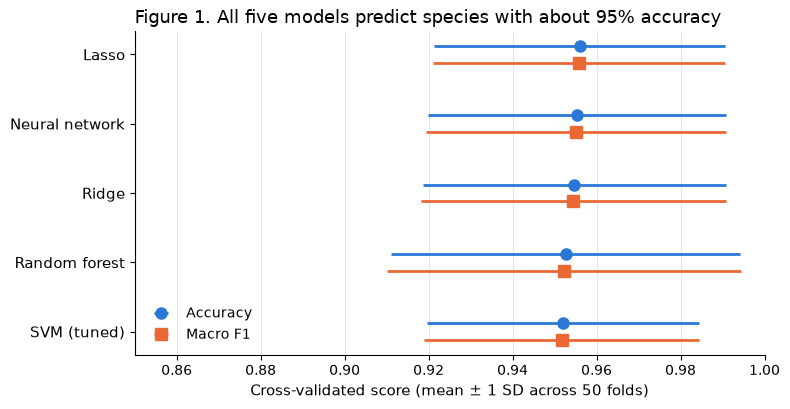

In [7]:

# Figure 1: mean accuracy and macro F1 per model with ±1 SD error bars
fig, ax = plt.subplots(figsize=(8, 4.2))
y_pos = np.arange(len(order))
style = {"Accuracy": ("#2a78d6", -0.12, "o"), "Macro F1": ("#eb6834", 0.12, "s")}

for metric, (color, offset, marker) in style.items():
    ax.errorbar(cv_mean.loc[order, metric], y_pos + offset,
                xerr=cv_sd.loc[order, metric], fmt=marker, color=color,
                markersize=8, elinewidth=2, capsize=0, label=metric)

ax.axvline(1/3, color="grey", lw=1, ls="--")
ax.set_yticks(y_pos, order, fontsize=11)
ax.invert_yaxis()
ax.set_xlim(0.85, 1.0)
ax.set_xlabel("Cross-validated score (mean ± 1 SD across 50 folds)", fontsize=11)
ax.set_title("Figure 1. All five models predict species with about 95% accuracy",
             fontsize=13, loc="left")
ax.grid(axis="x", color="#e5e5e5")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower left", frameon=False, fontsize=10)
plt.tight_layout()
plt.show()



**Interpretation.** All five models predict the species very well, at **about 95% accuracy**, far above the 33.3% you would get by always guessing the same species. Accuracy and macro F1 are almost identical for every model. This is expected because the classes are balanced, and it shows that no model is doing well overall at the cost of one species.

The gaps between models are small: the best and worst mean accuracies differ by less than one percentage point. In comparison, scores vary by about ±3–4 points from one fold to the next. With 30 flowers per test fold, one more or one fewer mistake already shifts accuracy by 3.3 points. So the ranking in Table 4 should not be over-read: **on this dataset, no method is clearly better than the others.**



### 2.3 SVM tuning results

The nested CV above gives an honest score for the *tuning procedure*. To report which settings it chooses, I also run the grid search once on the full dataset. Figure 2 shows the average 5-fold accuracy for every combination of `C` and `gamma`.


Best parameters: C = 10, gamma = 0.01  (mean CV accuracy = 0.973)


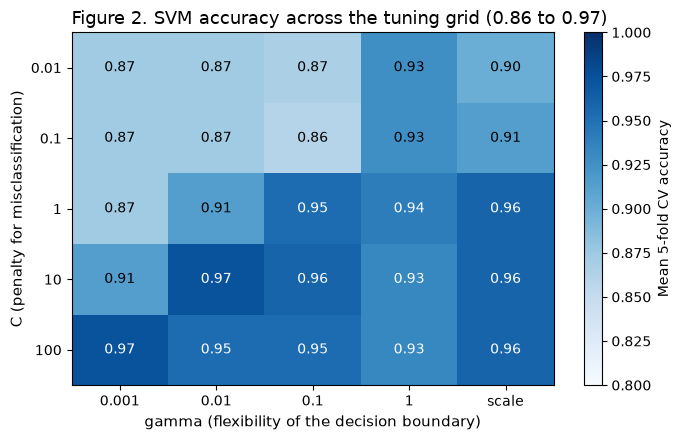

In [8]:

# Run the grid search once on all data to see the chosen settings
svm_tuned.fit(X, y)

grid_res = pd.DataFrame(svm_tuned.cv_results_)
grid_res["C"] = grid_res["param_svm__C"]
grid_res["gamma"] = grid_res["param_svm__gamma"].astype(str)
heat = grid_res.pivot(index="C", columns="gamma", values="mean_test_score")
heat = heat[["0.001", "0.01", "0.1", "1", "scale"]]
heat.index = [f"{c:g}" for c in heat.index]   # 1.0 -> 1

best = svm_tuned.best_params_
print(f"Best parameters: C = {best['svm__C']}, gamma = {best['svm__gamma']}  "
      f"(mean CV accuracy = {svm_tuned.best_score_:.3f})")

# Figure 2: heatmap of mean CV accuracy over the grid
fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(heat.values, cmap="Blues", vmin=0.80, vmax=1.0, aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=10,
                color="white" if v > 0.93 else "black")
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.set_xlabel("gamma (flexibility of the decision boundary)", fontsize=11)
ax.set_ylabel("C (penalty for misclassification)", fontsize=11)
ax.set_title("Figure 2. SVM accuracy across the tuning grid (0.86 to 0.97)",
             fontsize=13, loc="left")
fig.colorbar(im, ax=ax, label="Mean 5-fold CV accuracy")
plt.tight_layout()
plt.show()



**Interpretation.** The grid search picks **C = 10 and gamma = 0.01**, with a mean CV accuracy of 0.973. Very small values of `C` (0.01, 0.1) give the weakest results (about 0.86–0.93), because the penalty for mistakes is too weak and the decision boundary underfits. When `C` is 1 or larger, most combinations reach 0.95–0.97.

The SVM still does not come out ahead in Table 4, for two reasons:

1. **The 0.973 is optimistic.** It is the best of 25 combinations, all scored on the same folds, so part of its advantage is luck in those particular splits. The nested CV score in Table 4 (0.952) is the honest estimate of how the tuned SVM performs on new data.
2. **The default settings already do well.** The scikit-learn default (`C = 1`, `gamma = "scale"`) scores 0.96 in this grid, about the same as the best combination. On a small, well-separated dataset like Iris, tuning has little room to help.


## 3. New Insight: Do the Models Make the Same Mistakes?

All five models reach about 95% accuracy. Are they wrong about the *same* flowers? To check, I use 5-fold cross-validation to predict every flower once with each model, then count how many of the 5 models get each flower wrong.

In [9]:
from sklearn.model_selection import cross_val_predict

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# One cross-validated prediction per flower for each model
preds = pd.DataFrame({name: cross_val_predict(model, X, y, cv=cv5)
                      for name, model in models.items()})

# How many of the 5 models misclassify each flower
n_wrong = (preds.ne(y, axis=0)).sum(axis=1)

wrong_table = (n_wrong.value_counts().sort_index()
               .rename_axis("Models that misclassify the flower")
               .to_frame("Number of flowers"))
wrong_table.style.set_caption("Table 5. How many models get each flower wrong")

,Number of flowers
Models that misclassify the flower,
0,137
1,6
3,2
4,1
5,4


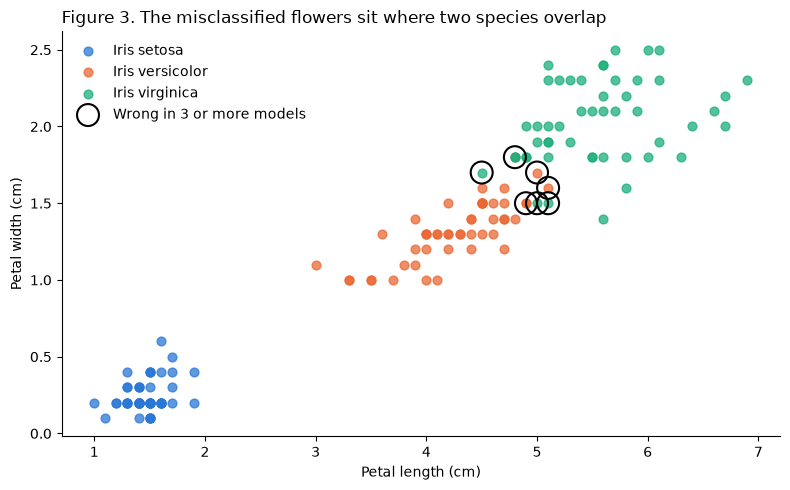

In [10]:
# Figure 3: petal measurements, with flowers missed by most models circled
colors = {"Iris-setosa": "#2a78d6", "Iris-versicolor": "#eb6834", "Iris-virginica": "#1baf7a"}
hard = n_wrong >= 3

fig, ax = plt.subplots(figsize=(8, 5))
for species, color in colors.items():
    m = y == species
    ax.scatter(X.loc[m, "petal length"], X.loc[m, "petal width"], color=color,
               s=40, alpha=0.75, label=species.replace("Iris-", "Iris "))
ax.scatter(X.loc[hard, "petal length"], X.loc[hard, "petal width"], s=250,
           facecolors="none", edgecolors="black", linewidths=1.5,
           label="Wrong in 3 or more models")

ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.set_title("Figure 3. The misclassified flowers sit where two species overlap", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 4. What We Learn

- **The models make the same mistakes.** Table 5 shows that 137 of the 150 flowers are classified correctly by all five models. Only 7 flowers are missed by three or more models, and 4 of them are missed by every model.
- **These flowers sit where two species overlap.** In Figure 3, every circled flower is a versicolor or virginica flower with petals that look like the other species. Setosa is never a problem.
- **The limit comes from the data, not the method.** No model can tell these flowers apart using only these four measurements. This is why all five models tie at about 95%: they all hit the same ceiling.

## 5. Recommendation

I recommend **lasso logistic regression** for predicting iris species.

- **It is as accurate as any other model.** It has the highest mean accuracy (0.956) and macro F1 (0.956) in Table 4. The gap to the other models is small, but no model beats it.
- **It is simple.** It is a linear model with no tuning, it trains in a fraction of a second, and it is easy to explain.
- **More complex models do not pay off.** The neural network, random forest and tuned SVM add complexity without improving accuracy. Section 3 explains why: the remaining errors come from flowers that overlap between species, which no model can fix.

Ridge logistic regression is an equally good choice: its results are nearly identical.